# RL advanced — RecurrentPPO + MPC with OU prediction

Two new agents to compare against vanilla PPO (experiment_5):
1. **RecurrentPPO** (LSTM policy) — captures OU temporal patterns
2. **MPC** with Monte-Carlo rollouts on learned OU dynamics — plans over horizon

Same library (25 actions), same OU noise, same aggregate reward structure.
Goal: close or surpass the 0.74 oracle ceiling.

## Imports

In [1]:
import os
import numpy as np
import torch
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import warnings
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import PPO
from sb3_contrib import RecurrentPPO
from stable_baselines3.common.callbacks import BaseCallback
from qiskit.quantum_info import Operator

warnings.filterwarnings('ignore')
np.random.seed(42)
torch.manual_seed(42)

## Config

In [2]:
OU_MU       = 0.10
OU_KAPPA    = 0.1
OU_SIGMA    = 0.03
P_MIN       = 0.01
P_MAX       = 0.30
F_THRESHOLD = 0.87
EPISODE_LEN = 50
DENSE_COEF  = 10.0
DET_PENALTY = 30.0
MARGIN_COEF = 3.0
MARGIN_TOL  = 0.01
TRAIN_STEPS = 3_000_000
TEST_EPS    = 50
LIB_PATHS   = {
    "safer":  "evolu_grid_safer_bitflip.pkl",
    "safe":   "evolu_grid_bitflip.pkl",
    "medium": "evolu_grid_medium_bitflip.pkl",
    "agg":    "evolu_grid_hard_bitflip.pkl",
}
N_ACTIONS   = 1 + sum(6 for _ in LIB_PATHS)
HIST_LEN    = 3
WIN_FAB     = 10
MPC_HORIZON = 5
MPC_SAMPLES = 30
MPC_VIOL_COEF = 20.0
MPC_SAFETY_MARGIN = 0.02
MPC_QUANTILE = 0.10
MPC_QUANTILE_PENALTY = 1000.0
P_GRID_SIZE = 100
RUN_TAG = "_v5"
TOP_K = 3
ENT_COEF = 0.10
LR_INIT  = 3e-4
N_EVAL   = 50
MASTER_SEED = int(np.random.default_rng().integers(1, 1_000_000))
print(f"Master seed for this run: {MASTER_SEED}")

Master seed for this run: 92883


## Physics

In [3]:
_I2 = torch.eye(2, dtype=torch.complex64)
_X  = torch.tensor([[0, 1], [1, 0]], dtype=torch.complex64)
_ket0 = torch.tensor([1, 0], dtype=torch.complex64)
_rho_eve = torch.outer(_ket0, _ket0.conj())

_LABELS = {
    '0': torch.tensor([1, 0], dtype=torch.complex64),
    '1': torch.tensor([0, 1], dtype=torch.complex64),
    '+': torch.tensor([1, 1], dtype=torch.complex64) / np.sqrt(2),
    '-': torch.tensor([1, -1], dtype=torch.complex64) / np.sqrt(2),
}

_bb84 = []
for label, psi in _LABELS.items():
    proj = torch.outer(psi, psi.conj())
    rho_clean = torch.kron(proj, _rho_eve)
    rho_flip  = torch.kron(_X @ proj @ _X.conj().T, _rho_eve)
    proj_A = torch.kron(proj, _I2)
    proj_E = torch.kron(_I2, proj)
    _bb84.append((rho_clean, rho_flip, proj_A, proj_E))

def compute_fidelities(U, p):
    f_ab = torch.zeros((), dtype=torch.float32)
    f_ae = torch.zeros((), dtype=torch.float32)
    for rho_clean, rho_flip, proj_A, proj_E in _bb84:
        rho_in  = (1 - p) * rho_clean + p * rho_flip
        rho_out = U @ rho_in @ U.conj().T
        f_ab = f_ab + torch.trace(proj_A @ rho_out).real
        f_ae = f_ae + torch.trace(proj_E @ rho_out).real
    return float(f_ab / 4), float(f_ae / 4)

def generate_ou_noise(n_steps, mu=OU_MU, kappa=OU_KAPPA, sigma=OU_SIGMA,
                     p_min=P_MIN, p_max=P_MAX, p0=None, seed=None):
    rng = np.random.default_rng(seed)
    noise = np.empty(n_steps)
    p = mu if p0 is None else p0
    decay = np.exp(-kappa)
    noise_std = sigma * np.sqrt((1 - np.exp(-2 * kappa)) / (2 * kappa))
    for i in range(n_steps):
        noise[i] = p
        p = mu + (p - mu) * decay + noise_std * rng.standard_normal()
        p = np.clip(p, p_min, p_max)
    return noise

## Library

In [4]:
grids = {}
for name, path in LIB_PATHS.items():
    with open(path, "rb") as f:
        grids[name] = pickle.load(f)

def _extract_best_U(res):
    best_list, _, _, history_list, _ = res
    loss = np.array([h["best"]["loss"][-1] for h in history_list])
    i = int(np.argmin(loss))
    U = torch.tensor(Operator(best_list[i]).data, dtype=torch.complex64)
    return U, best_list[i], {"f_ab": history_list[i]["best"]["f_ab"][-1],
                             "f_ae": history_list[i]["best"]["f_ae"][-1]}

ps_sorted = sorted(grids["safe"].keys())
Us = {name: [] for name in LIB_PATHS}
circuits = {name: [] for name in LIB_PATHS}
meta = {name: [] for name in LIB_PATHS}

for p in ps_sorted:
    for name in LIB_PATHS:
        U, c, m = _extract_best_U(grids[name][p])
        Us[name].append(U); circuits[name].append(c); meta[name].append(m)

library_U = torch.stack([torch.eye(4, dtype=torch.complex64)] +
                        [u for name in LIB_PATHS for u in Us[name]])
library_labels = ["identity"] + [f"{name}_p{p}" for name in LIB_PATHS for p in ps_sorted]
assert len(library_U) == N_ACTIONS

In [5]:
P_GRID = np.linspace(P_MIN, P_MAX, P_GRID_SIZE)
fab_table = np.zeros((N_ACTIONS, P_GRID_SIZE))
fae_table = np.zeros((N_ACTIONS, P_GRID_SIZE))
for a in range(N_ACTIONS):
    for i, p in enumerate(P_GRID):
        fab_table[a, i], fae_table[a, i] = compute_fidelities(library_U[a], float(p))

def lookup_fidelities(a, p):
    x = (np.clip(p, P_MIN, P_MAX) - P_MIN) / (P_MAX - P_MIN) * (P_GRID_SIZE - 1)
    i_lo = int(x)
    i_hi = min(i_lo + 1, P_GRID_SIZE - 1)
    alpha = x - i_lo
    fab = (1 - alpha) * fab_table[a, i_lo] + alpha * fab_table[a, i_hi]
    fae = (1 - alpha) * fae_table[a, i_lo] + alpha * fae_table[a, i_hi]
    return float(fab), float(fae)

print(f"Fidelity table ready: {fab_table.shape}")

Fidelity table ready: (25, 100)


In [6]:
_rng = np.random.default_rng(0)
_n_stat = 5000
_p_stat = np.clip(OU_MU + (OU_SIGMA / np.sqrt(2 * OU_KAPPA)) * _rng.standard_normal(_n_stat), P_MIN, P_MAX)
_fab_fb_sum, _fae_fb_sum = 0.0, 0.0
for _p in _p_stat:
    _a = 1 + int(np.argmin([abs(pl - _p) for pl in ps_sorted]))
    _fab, _fae = lookup_fidelities(_a, float(_p))
    _fab_fb_sum += _fab; _fae_fb_sum += _fae
FAB_FALLBACK_AVG = _fab_fb_sum / _n_stat
FAE_FALLBACK_AVG = _fae_fb_sum / _n_stat
print(f"Fallback empirical: F_AB={FAB_FALLBACK_AVG:.4f}, F_AE={FAE_FALLBACK_AVG:.4f}")

Fallback empirical: F_AB=0.8899, F_AE=0.7216


## Environment

In [7]:
class LibraryEnv(gym.Env):
    def __init__(self, mu=OU_MU, kappa=OU_KAPPA, sigma=OU_SIGMA,
                 p_min=P_MIN, p_max=P_MAX, episode_len=EPISODE_LEN,
                 f_threshold=F_THRESHOLD, dense_coef=DENSE_COEF, det_penalty=DET_PENALTY,
                 margin_coef=MARGIN_COEF, margin_tol=MARGIN_TOL):
        super().__init__()
        self.mu = mu
        self.kappa = kappa
        self.sigma = sigma
        self.p_min = p_min
        self.p_max = p_max
        self.episode_len = episode_len
        self.f_threshold = f_threshold
        self.dense_coef = dense_coef
        self.det_penalty = det_penalty
        self.margin_coef = margin_coef
        self.margin_tol = margin_tol
        self.action_space = spaces.Discrete(N_ACTIONS)
        self.observation_space = spaces.Box(
            low=np.float32(-1.0), high=np.float32(2.0),
            shape=(8,), dtype=np.float32)

    def _obs(self):
        recent = self.f_ab_ep[-WIN_FAB:] if self.f_ab_ep else [1.0]
        return np.array([
            self.p,
            self.p_hist[-1] if len(self.p_hist) >= 1 else self.p,
            self.p_hist[-2] if len(self.p_hist) >= 2 else self.p,
            self.p_hist[-3] if len(self.p_hist) >= 3 else self.p,
            self.last_action / (N_ACTIONS - 1),
            float(np.mean(recent)),
            float(np.mean(self.f_ae_ep)) if self.f_ae_ep else 0.5,
            (self.episode_len - self.t) / self.episode_len,
        ], dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.p = float(self.mu + self.sigma * self.np_random.standard_normal())
        self.p = float(np.clip(self.p, self.p_min, self.p_max))
        self.p_hist = []
        self.last_action = 0
        self.f_ab_ep = []
        self.f_ae_ep = []
        self.t = 0
        return self._obs(), {}

    def step(self, action):
        U = library_U[int(action)]
        f_ab, f_ae = compute_fidelities(U, self.p)
        self.p_hist.append(self.p)
        if len(self.p_hist) > HIST_LEN:
            self.p_hist.pop(0)
        self.last_action = int(action)
        self.f_ab_ep.append(f_ab)
        self.f_ae_ep.append(f_ae)
        self.t += 1

        reward = f_ae - 0.5
        running_fab = float(np.mean(self.f_ab_ep))
        if running_fab < self.f_threshold:
            reward -= self.dense_coef * (self.f_threshold - running_fab)
        else:
            excess = running_fab - self.f_threshold
            if excess > self.margin_tol:
                reward -= self.margin_coef * (excess - self.margin_tol)
        done = self.t >= self.episode_len
        if done and running_fab < self.f_threshold:
            reward -= self.det_penalty

        decay = np.exp(-self.kappa)
        noise_std = self.sigma * np.sqrt((1 - np.exp(-2 * self.kappa)) / (2 * self.kappa))
        self.p = self.mu + (self.p - self.mu) * decay + noise_std * self.np_random.standard_normal()
        self.p = float(np.clip(self.p, self.p_min, self.p_max))

        info = {"f_ab": f_ab, "f_ae": f_ae, "p": self.p,
                "mean_fab_ep": running_fab}
        return self._obs(), float(reward), done, False, info

## Training — RecurrentPPO (LSTM policy)

In [8]:
class BestModelCallback(BaseCallback):
    def __init__(self, save_prefix, k=3, eval_freq=10000, n_eval=20, is_recurrent=False):
        super().__init__()
        self.save_prefix = save_prefix
        self.k = k
        self.eval_freq = eval_freq
        self.n_eval = n_eval
        self.is_recurrent = is_recurrent
        self.top = []
        self.best_score = -np.inf
        self.best_step = 0
        self.history = []

    def _on_step(self):
        if self.num_timesteps % self.eval_freq == 0:
            env = LibraryEnv()
            faes, fabs, dets = [], [], 0
            for ep in range(self.n_eval):
                seed = (MASTER_SEED + self.num_timesteps + ep) % (2**31 - 1)
                obs, _ = env.reset(seed=int(seed))
                done = False
                lstm_states = None
                episode_starts = np.ones((1,), dtype=bool)
                while not done:
                    if self.is_recurrent:
                        a, lstm_states = self.model.predict(
                            obs, state=lstm_states,
                            episode_start=episode_starts,
                            deterministic=True)
                        episode_starts = np.zeros((1,), dtype=bool)
                    else:
                        a, _ = self.model.predict(obs, deterministic=True)
                    obs, r, done, _, info = env.step(a)
                faes.append(np.mean(env.f_ae_ep))
                fabs.append(np.mean(env.f_ab_ep))
                if np.mean(env.f_ab_ep) < F_THRESHOLD:
                    dets += 1
            mfae, mfab, drate = float(np.mean(faes)), float(np.mean(fabs)), dets / self.n_eval
            self.history.append({"step": self.num_timesteps, "f_ae": mfae, "f_ab": mfab, "det": drate})
            score = mfae - 2.0 * drate
            if len(self.top) < self.k or score > min(s for s, _, _ in self.top):
                path = f"{self.save_prefix}_top{self.num_timesteps}"
                self.model.save(path)
                self.top.append((score, self.num_timesteps, path))
                self.top.sort(reverse=True)
                if len(self.top) > self.k:
                    _, _, drop_path = self.top.pop()
                    try:
                        os.remove(drop_path + ".zip")
                    except Exception:
                        pass
            if score > self.best_score:
                self.best_score = score
                self.best_step = self.num_timesteps
                self.model.save(self.save_prefix)
            print(f"  [Eval @ {self.num_timesteps:,}] F_AE={mfae:.4f}  F_AB={mfab:.4f}  det={drate*100:.1f}%")
        return True

In [9]:
from stable_baselines3.common.vec_env import SubprocVecEnv

N_ENVS = 4

_env_seeds = np.random.default_rng(MASTER_SEED).integers(1, 1_000_000, size=N_ENVS)
print(f"Training env seeds: {_env_seeds.tolist()}")

def make_env(rank):
    seed_rank = int(_env_seeds[rank])
    def _init():
        env = LibraryEnv()
        env.reset(seed=seed_rank)
        return env
    return _init

train_env_rec = SubprocVecEnv([make_env(i) for i in range(N_ENVS)])
best_cb_rec = BestModelCallback(f"ppo_recurrent_best{RUN_TAG}", k=TOP_K,
                                 eval_freq=10000, n_eval=N_EVAL, is_recurrent=True)

lr_schedule = lambda progress: LR_INIT * (0.2 + 0.8 * progress)

model_rec = RecurrentPPO("MlpLstmPolicy", train_env_rec, verbose=0,
    device="cpu",
    learning_rate=lr_schedule,
    n_steps=128, batch_size=64, n_epochs=10,
    gamma=0.99, ent_coef=ENT_COEF, clip_range=0.2, seed=MASTER_SEED,
    policy_kwargs=dict(lstm_hidden_size=64, enable_critic_lstm=True))

model_rec.learn(total_timesteps=TRAIN_STEPS, callback=best_cb_rec)
model_rec = RecurrentPPO.load(f"ppo_recurrent_best{RUN_TAG}", device="cpu")
print(f"Best: step={best_cb_rec.best_step}, score={best_cb_rec.best_score:.4f}")
print(f"Top-{TOP_K} checkpoints:")
for s, step, path in best_cb_rec.top:
    print(f"  score={s:.4f}  step={step}  path={path}.zip")

Training env seeds: [637719, 826161, 594599, 374823]
  [Eval @ 10,000] F_AE=0.6471  F_AB=0.9164  det=0.0%
  [Eval @ 20,000] F_AE=0.5000  F_AB=0.9457  det=0.0%
  [Eval @ 30,000] F_AE=0.7491  F_AB=0.8633  det=62.0%
  [Eval @ 40,000] F_AE=0.7644  F_AB=0.8570  det=80.0%
  [Eval @ 50,000] F_AE=0.7119  F_AB=0.8971  det=2.0%
  [Eval @ 60,000] F_AE=0.6816  F_AB=0.9120  det=0.0%
  [Eval @ 70,000] F_AE=0.7070  F_AB=0.8944  det=2.0%
  [Eval @ 80,000] F_AE=0.5021  F_AB=0.9423  det=0.0%
  [Eval @ 90,000] F_AE=0.7241  F_AB=0.8834  det=14.0%
  [Eval @ 100,000] F_AE=0.5820  F_AB=0.9414  det=0.0%
  [Eval @ 110,000] F_AE=0.7337  F_AB=0.8692  det=54.0%
  [Eval @ 120,000] F_AE=0.6076  F_AB=0.9140  det=0.0%
  [Eval @ 130,000] F_AE=0.7361  F_AB=0.8715  det=44.0%
  [Eval @ 140,000] F_AE=0.7294  F_AB=0.8740  det=44.0%
  [Eval @ 150,000] F_AE=0.7343  F_AB=0.8787  det=24.0%
  [Eval @ 160,000] F_AE=0.7314  F_AB=0.8794  det=28.0%
  [Eval @ 170,000] F_AE=0.7228  F_AB=0.8861  det=16.0%
  [Eval @ 180,000] F_AE=0.718

## MPC — Monte Carlo rollouts on OU dynamics

In [10]:
def mpc_policy_factory(horizon=MPC_HORIZON, n_samples=MPC_SAMPLES, viol_coef=MPC_VIOL_COEF,
                       mode="base", safety_margin=MPC_SAFETY_MARGIN,
                       quantile=MPC_QUANTILE, quantile_penalty=MPC_QUANTILE_PENALTY):
    decay = np.exp(-OU_KAPPA)
    noise_std = OU_SIGMA * np.sqrt((1 - np.exp(-2 * OU_KAPPA)) / (2 * OU_KAPPA))

    def policy(obs, env):
        p_now = float(obs[0])
        steps_done = len(env.f_ab_ep)
        remaining = env.episode_len - steps_done
        if remaining <= 0:
            return 0
        f_ab_so_far_sum = sum(env.f_ab_ep)
        h = min(horizon, remaining - 1)

        rng = np.random.default_rng(42 + steps_done)
        if h > 0:
            p_paths = np.zeros((n_samples, h))
            for i in range(n_samples):
                p = p_now
                for k in range(h):
                    p = env.mu + (p - env.mu) * decay + noise_std * rng.standard_normal()
                    p = float(np.clip(p, env.p_min, env.p_max))
                    p_paths[i, k] = p
        else:
            p_paths = np.zeros((n_samples, 0))

        effective_threshold = env.f_threshold + (safety_margin if mode == "margin" else 0.0)

        best_a, best_score = 0, -np.inf
        for a in range(N_ACTIONS):
            f_ab_a, f_ae_a = lookup_fidelities(a, p_now)
            faes_future = np.zeros(n_samples)
            fabs_future = np.zeros(n_samples)
            for i in range(n_samples):
                fae_cum = f_ae_a
                fab_cum = f_ab_so_far_sum + f_ab_a
                for k in range(h):
                    p_future = p_paths[i, k]
                    a_fb = 1 + int(np.argmin([abs(pl - p_future) for pl in ps_sorted]))
                    fab_f, fae_f = lookup_fidelities(a_fb, p_future)
                    fae_cum += fae_f
                    fab_cum += fab_f
                steps_after = remaining - 1 - h
                if steps_after > 0:
                    fae_cum += steps_after * FAE_FALLBACK_AVG
                    fab_cum += steps_after * FAB_FALLBACK_AVG
                faes_future[i] = fae_cum / remaining
                fabs_future[i] = fab_cum / env.episode_len

            exp_fae = float(np.mean(faes_future))
            if mode == "quantile":
                fab_low = float(np.quantile(fabs_future, quantile))
                if fab_low < env.f_threshold:
                    score = exp_fae - quantile_penalty * (env.f_threshold - fab_low)
                else:
                    score = exp_fae
            else:
                viol_rate = float(np.mean(fabs_future < effective_threshold))
                score = exp_fae - viol_coef * viol_rate
            if score > best_score:
                best_score = score
                best_a = a
        return best_a
    return policy

mpc_policy        = mpc_policy_factory(mode="base")
mpc_policy_margin = mpc_policy_factory(mode="margin")
mpc_policy_quant  = mpc_policy_factory(mode="quantile")

env_test = LibraryEnv()
obs, _ = env_test.reset(seed=0)
print(f"MPC base:     {mpc_policy(obs, env_test)} ({library_labels[mpc_policy(obs, env_test)]})")
print(f"MPC margin:   {mpc_policy_margin(obs, env_test)} ({library_labels[mpc_policy_margin(obs, env_test)]})")
print(f"MPC quantile: {mpc_policy_quant(obs, env_test)} ({library_labels[mpc_policy_quant(obs, env_test)]})")

MPC base:     19 (agg_p0.02)
MPC margin:   6 (safer_p0.25)
MPC quantile: 19 (agg_p0.02)


## Evaluation

In [11]:
SAFER_OFFSET = 1

def rec_policy(obs, env, _state={"lstm": None, "starts": None}):
    if _state["lstm"] is None or env.t == 0:
        _state["lstm"] = None
        _state["starts"] = np.ones((1,), dtype=bool)
    a, _state["lstm"] = model_rec.predict(
        obs, state=_state["lstm"],
        episode_start=_state["starts"],
        deterministic=True)
    _state["starts"] = np.zeros((1,), dtype=bool)
    return int(a)

def static_safe_policy(obs, env):
    p = obs[0]
    return SAFER_OFFSET + int(np.argmin([abs(pl - p) for pl in ps_sorted]))

def identity_policy(obs, env):
    return 0

def oracle_policy(obs, env):
    p = obs[0]
    best_a, best_fae = 0, -np.inf
    for a in range(N_ACTIONS):
        f_ab, f_ae = lookup_fidelities(a, float(p))
        if f_ab >= env.f_threshold and f_ae > best_fae:
            best_fae = f_ae
            best_a = a
    return best_a

POLICIES = {
    "RecurrentPPO":  rec_policy,
    "MPC base":      mpc_policy,
    "MPC margin":    mpc_policy_margin,
    "MPC quantile":  mpc_policy_quant,
    "Static safe":   static_safe_policy,
    "Oracle":        oracle_policy,
    "Identity":      identity_policy,
}

In [12]:
def run_episode(policy_fn, env_seed):
    env = LibraryEnv()
    obs, _ = env.reset(seed=env_seed)
    done = False
    actions = []
    while not done:
        a = policy_fn(obs, env)
        actions.append(a)
        obs, r, done, _, info = env.step(a)
    return np.mean(env.f_ae_ep), np.mean(env.f_ab_ep), actions

TEST_SEED_BASE = (MASTER_SEED + 1_000_000_000) % (2**31 - 1)

results = {name: {"f_ae": [], "f_ab": [], "det": 0, "actions": []} for name in POLICIES}
for name, pol in POLICIES.items():
    print(f"Eval {name}...")
    for ep in range(TEST_EPS):
        seed = (TEST_SEED_BASE + ep) % (2**31 - 1)
        fae, fab, actions = run_episode(pol, env_seed=int(seed))
        results[name]["f_ae"].append(fae)
        results[name]["f_ab"].append(fab)
        results[name]["actions"].extend(actions)
        if fab < F_THRESHOLD:
            results[name]["det"] += 1

rows = []
for name, r in results.items():
    rows.append({
        "Method":    name,
        "Mean F_AE": f"{np.mean(r['f_ae']):.4f}",
        "Std F_AE":  f"{np.std(r['f_ae']):.4f}",
        "Mean F_AB": f"{np.mean(r['f_ab']):.4f}",
        "Det. rate": f"{r['det'] / TEST_EPS * 100:.1f}%",
    })
pd.DataFrame(rows).set_index("Method")

Eval RecurrentPPO...


Eval MPC base...
Eval MPC margin...
Eval MPC quantile...
Eval Static safe...
Eval Oracle...
Eval Identity...


,Mean F_AE,Std F_AE,Mean F_AB,Det. rate
Method,,,,
RecurrentPPO,0.7262,0.0254,0.8833,0.0%
MPC base,0.7262,0.0380,0.8625,6.0%
MPC margin,0.7092,0.0389,0.8825,6.0%
MPC quantile,0.7202,0.0385,0.8701,10.0%
Static safe,0.7182,0.0268,0.8898,0.0%
Oracle,0.7423,0.0267,0.8753,0.0%
Identity,0.5000,0.0000,0.9467,0.0%


In [13]:
def run_episode(policy_fn, env_seed):
    env = LibraryEnv()
    obs, _ = env.reset(seed=env_seed)
    done = False
    actions = []
    while not done:
        a = policy_fn(obs, env)
        actions.append(a)
        obs, r, done, _, info = env.step(a)
    return np.mean(env.f_ae_ep), np.mean(env.f_ab_ep), actions

def make_rec_policy(model):
    state = {"lstm": None, "starts": np.ones((1,), dtype=bool)}
    def policy(obs, env):
        if env.t == 0:
            state["lstm"] = None
            state["starts"] = np.ones((1,), dtype=bool)
        a, state["lstm"] = model.predict(
            obs, state=state["lstm"],
            episode_start=state["starts"],
            deterministic=True)
        state["starts"] = np.zeros((1,), dtype=bool)
        return int(a)
    return policy

TEST_SEED_BASE = (MASTER_SEED + 1_000_000_000) % (2**31 - 1)

POLICIES_EVAL = {}
for rank, (train_score, step, path) in enumerate(best_cb_rec.top, 1):
    m = RecurrentPPO.load(path, device="cpu")
    POLICIES_EVAL[f"RL top-{rank} (step {step})"] = make_rec_policy(m)
for k, v in POLICIES.items():
    if k != "RecurrentPPO":
        POLICIES_EVAL[k] = v

results = {name: {"f_ae": [], "f_ab": [], "det": 0, "actions": []} for name in POLICIES_EVAL}
for name, pol in POLICIES_EVAL.items():
    print(f"Eval {name}...")
    for ep in range(TEST_EPS):
        seed = (TEST_SEED_BASE + ep) % (2**31 - 1)
        fae, fab, actions = run_episode(pol, env_seed=int(seed))
        results[name]["f_ae"].append(fae)
        results[name]["f_ab"].append(fab)
        results[name]["actions"].extend(actions)
        if fab < F_THRESHOLD:
            results[name]["det"] += 1

rows = []
for name, r in results.items():
    rows.append({
        "Method":    name,
        "Mean F_AE": f"{np.mean(r['f_ae']):.4f}",
        "Std F_AE":  f"{np.std(r['f_ae']):.4f}",
        "Mean F_AB": f"{np.mean(r['f_ab']):.4f}",
        "Det. rate": f"{r['det'] / TEST_EPS * 100:.1f}%",
    })
pd.DataFrame(rows).set_index("Method")

Eval RL top-1 (step 2560000)...
Eval RL top-2 (step 2450000)...
Eval RL top-3 (step 1130000)...
Eval MPC base...
Eval MPC margin...
Eval MPC quantile...
Eval Static safe...
Eval Oracle...
Eval Identity...


,Mean F_AE,Std F_AE,Mean F_AB,Det. rate
Method,,,,
RL top-1 (step 2560000),0.7262,0.0254,0.8833,0.0%
RL top-2 (step 2450000),0.7268,0.0280,0.8813,2.0%
RL top-3 (step 1130000),0.7240,0.0177,0.8857,2.0%
MPC base,0.7262,0.0380,0.8625,6.0%
MPC margin,0.7092,0.0389,0.8825,6.0%
MPC quantile,0.7202,0.0385,0.8701,10.0%
Static safe,0.7182,0.0268,0.8898,0.0%
Oracle,0.7423,0.0267,0.8753,0.0%
Identity,0.5000,0.0000,0.9467,0.0%


## Plots

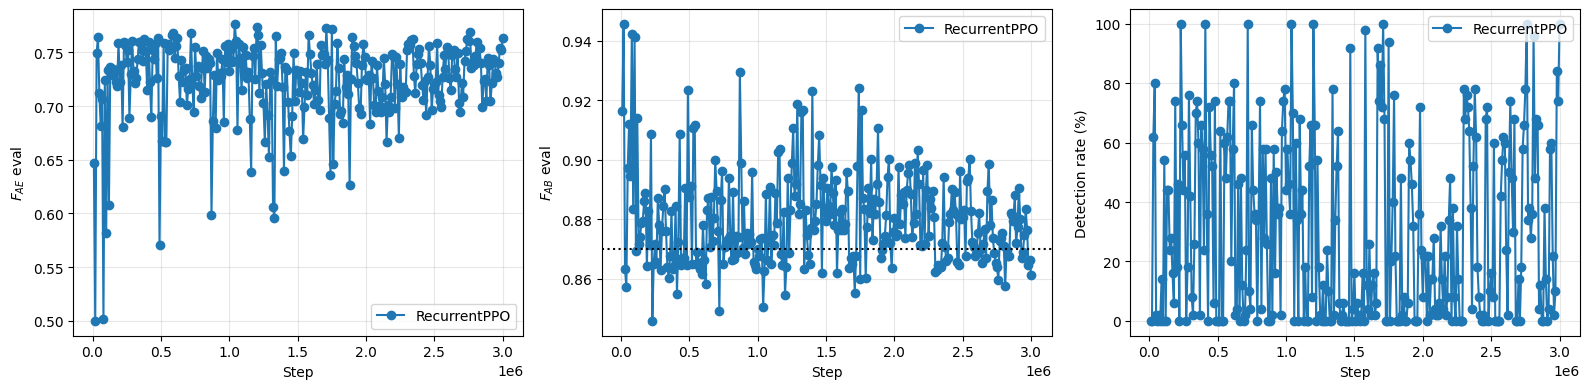

In [14]:
hist_df = pd.DataFrame(best_cb_rec.history)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(hist_df["step"], hist_df["f_ae"], "o-", label="RecurrentPPO")
axes[0].set_xlabel("Step"); axes[0].set_ylabel("$F_{AE}$ eval"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(hist_df["step"], hist_df["f_ab"], "o-", label="RecurrentPPO")
axes[1].axhline(F_THRESHOLD, color="k", ls=":")
axes[1].set_xlabel("Step"); axes[1].set_ylabel("$F_{AB}$ eval"); axes[1].legend(); axes[1].grid(alpha=0.3)
axes[2].plot(hist_df["step"], hist_df["det"] * 100, "o-", label="RecurrentPPO")
axes[2].set_xlabel("Step"); axes[2].set_ylabel("Detection rate (%)"); axes[2].legend(); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

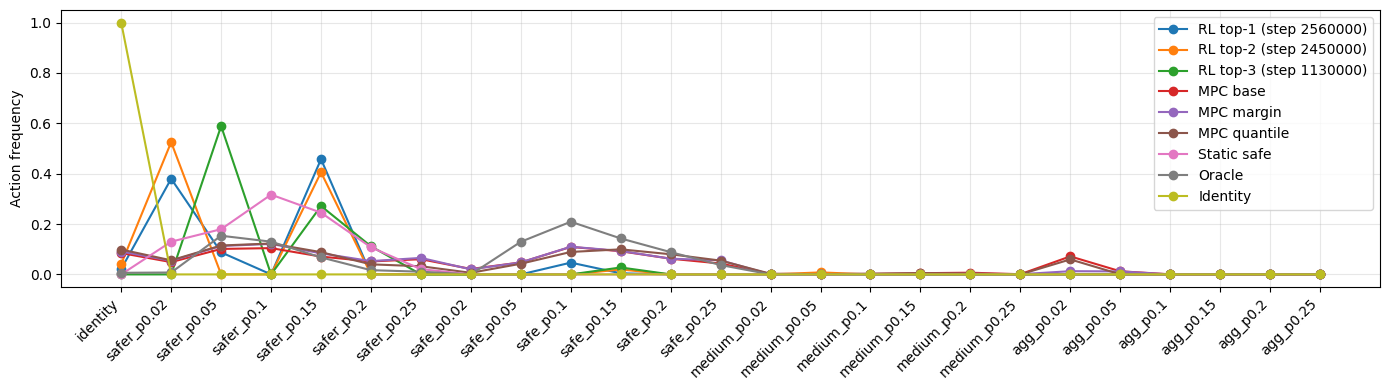

In [15]:
fig, ax = plt.subplots(figsize=(14, 4))
for name, r in results.items():
    counts = np.bincount(r["actions"], minlength=N_ACTIONS)
    ax.plot(range(N_ACTIONS), counts / counts.sum(), "o-", label=name)
ax.set_xticks(range(N_ACTIONS))
ax.set_xticklabels(library_labels, rotation=45, ha="right")
ax.set_ylabel("Action frequency")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [16]:
with open(f"exp6_results{RUN_TAG}.pkl", "wb") as f:
    pickle.dump({"results": results, "history_rec": best_cb_rec.history}, f)